# DataCo Smart Supply Chain: segmentación no supervisada de pedidos

**Proyecto integrador - Aprendizaje de Máquina No Supervisado**

## Pregunta de análisis
¿Se pueden descubrir perfiles de pedidos por su composición, economía y condiciones de despacho planificadas, y qué pedidos merecen revisión por ser atípicos?

La unidad de análisis será el **pedido** (no la línea de producto). Se comparan K-Means como línea base y Gaussian Mixture Models (GMM) como alternativa probabilística; PCA se usa para estudiar y visualizar la representación, e Isolation Forest para priorizar anomalías.

> El PDF describe un proyecto integrador no supervisado y DataCo es el dataset de la lista. No hay un apartado rotulado literalmente “Ejercicio 2”; este notebook implementa la ruta y los entregables pertinentes al proyecto con DataCo.

### Reproducibilidad
Ejecutar de arriba abajo desde el directorio del proyecto. Se leen las fuentes de `raw data/` y se escribe `treated data/DataCoSmartSupplyChain_clean.csv`. Semilla: 42. Dependencias: Python, pandas, numpy, matplotlib, seaborn, scipy y scikit-learn.

Este notebook es el entregable reproducible completo: contiene perfiles, metricas, sensibilidad, CV, visualizaciones, conclusiones, limitaciones y una guia de sustentacion; no requiere archivos de resultados adicionales para entender el analisis.

In [1]:
from pathlib import Path
import re
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor
from sklearn.model_selection import KFold
from sklearn.manifold import trustworthiness
from scipy.special import rel_entr
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in _candidates if (path / "raw data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontro la carpeta 'raw data' desde el directorio actual.")
RAW_DIR = ROOT / "raw data"
TREATED_DIR = ROOT / "treated data"
TREATED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Proyecto: {ROOT}")
print(f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | semilla {SEED}")

Proyecto: C:\Users\L0s3r\OneDrive\Escritorio\unsuppervised
pandas 2.3.3 | scikit-learn 1.8.0 | semilla 42


## 1. Fuentes, unidad de registro y calidad inicial

La tabla principal contiene líneas de pedido. Los otros archivos son un diccionario de campos y logs de navegación; se evalúa su integración por separado antes de modelar.

In [2]:
main_path = RAW_DIR / "DataCoSupplyChainDataset.csv"
dictionary_path = RAW_DIR / "DescriptionDataCoSupplyChain.csv"
logs_path = RAW_DIR / "tokenized_access_logs.csv"

main = pd.read_csv(main_path, encoding="latin1", low_memory=False)
dictionary = pd.read_csv(dictionary_path, encoding="latin1", low_memory=False)
logs = pd.read_csv(logs_path, encoding="latin1", low_memory=False)

print("Tabla principal:", main.shape)
print("Diccionario:", dictionary.shape)
print("Logs:", logs.shape)
print("Tipos de datos en tabla principal:\n", main.dtypes.value_counts().to_string())
print("Rango bruto de columnas principales:", len(main.columns))

Tabla principal: (180519, 53)
Diccionario: (52, 2)
Logs: (469977, 8)
Tipos de datos en tabla principal:
 object     24
float64    15
int64      14
Rango bruto de columnas principales: 53


In [3]:
order_date = pd.to_datetime(
    main["order date (DateOrders)"], format="%m/%d/%Y %H:%M", errors="coerce"
)
shipping_date = pd.to_datetime(
    main["shipping date (DateOrders)"], format="%m/%d/%Y %H:%M", errors="coerce"
)
quality = pd.DataFrame({
    "filas": [len(main)],
    "columnas": [main.shape[1]],
    "filas_duplicadas": [int(main.duplicated().sum())],
    "Order Item Id duplicados": [int(main["Order Item Id"].duplicated().sum())],
    "pedidos unicos": [int(main["Order Id"].nunique())],
    "valores faltantes": [int(main.isna().sum().sum())],
    "fechas de pedido invalidas": [int(order_date.isna().sum())],
    "fechas de envio invalidas": [int(shipping_date.isna().sum())],
    "pedido con fecha de envio anterior": [int((shipping_date < order_date).sum())],
})
quality.T.rename(columns={0: "valor"})

,valor
filas,180519
columnas,53
filas_duplicadas,0
Order Item Id duplicados,0
pedidos unicos,65752
valores faltantes,336209
fechas de pedido invalidas,0
fechas de envio invalidas,0
pedido con fecha de envio anterior,0


## 2. Integración y decisión de no fusionar los logs

El diccionario se compara por nombre normalizado de campo. Para los logs se mide coincidencia exacta de nombres de producto normalizados y cobertura de líneas, además de revisar fechas y llaves. Una unión por producto no equivale a una unión pedido-cliente: no hay identificador compartido de pedido/cliente y los logs contienen IPs, que no se usarán como atributos.

In [4]:
def normalize_name(value):
    return re.sub(r"\s+", " ", str(value)).strip().casefold()

main_names = {normalize_name(col) for col in main.columns}
dictionary_names = {normalize_name(value) for value in dictionary["FIELDS"].dropna()}
missing_in_dictionary = sorted(main_names - dictionary_names)
extra_in_dictionary = sorted(dictionary_names - main_names)

def normalize_product(series):
    return series.fillna("").astype(str).str.strip().str.casefold()

main_products = normalize_product(main["Product Name"])
log_products = normalize_product(logs["Product"])
product_overlap = set(main_products) & set(log_products)
logs["Date_parsed"] = pd.to_datetime(
    logs["Date"], format="%m/%d/%Y %H:%M", errors="coerce"
)
order_dates = order_date
log_dates = logs["Date_parsed"]

integration_evidence = pd.Series({
    "campos en tabla principal": len(main_names),
    "campos en diccionario": len(dictionary_names),
    "campos sin descripcion": len(missing_in_dictionary),
    "campos sobrantes en diccionario": len(extra_in_dictionary),
    "productos unicos DataCo": main_products.nunique(),
    "productos unicos en logs": log_products.nunique(),
    "productos coincidentes exactos": len(product_overlap),
    "cobertura de productos unicos DataCo": len(product_overlap) / main_products.nunique(),
    "cobertura de lineas DataCo por nombre de producto": main_products.isin(product_overlap).mean(),
    "cobertura de filas de logs por nombre de producto": log_products.isin(product_overlap).mean(),
    "filas de logs con fecha invalida": int(log_dates.isna().sum()),
})
print("Campos DataCo sin descripcion:", missing_in_dictionary)
print("Campos sobrantes en diccionario:", extra_in_dictionary)
print("Evidencia de integracion:\n", integration_evidence.to_string())
print("Fechas DataCo:", order_dates.min(), "a", order_dates.max())
print("Fechas logs:", log_dates.min(), "a", log_dates.max())
print("Columnas logs disponibles:", list(logs.columns))

Campos DataCo sin descripcion: ['order zipcode']
Campos sobrantes en diccionario: []
Evidencia de integracion:
 campos en tabla principal                             53.000000
campos en diccionario                                 52.000000
campos sin descripcion                                 1.000000
campos sobrantes en diccionario                        0.000000
productos unicos DataCo                              118.000000
productos unicos en logs                              76.000000
productos coincidentes exactos                        72.000000
cobertura de productos unicos DataCo                   0.610169
cobertura de lineas DataCo por nombre de producto      0.930578
cobertura de filas de logs por nombre de producto      0.921143
filas de logs con fecha invalida                       0.000000
Fechas DataCo: 2015-01-01 00:00:00 a 2018-01-31 23:38:00
Fechas logs: 2017-09-01 06:00:00 a 2018-01-31 23:58:00
Columnas logs disponibles: ['Product', 'Category', 'Date', 'Month', 'Hou

**Decisión de integración.** Se usa el diccionario como documentación, no como tabla de hechos. No se integran los logs: aunque nombres de productos coinciden parcialmente y cubren una fracción relevante de líneas, solo coinciden una parte de los productos únicos, las fuentes no comparten llave de pedido o cliente y el periodo de navegación es una ventana parcial. Una asignación de visitas por producto generaría una variable ecológica, temporalmente incompleta y con cobertura desigual; tampoco sería válido equiparar IP con cliente.

## 3. Limpieza y exportación

Se conserva la granularidad línea de pedido y sus llaves de pedido/ítem. Se eliminan atributos personales del cliente, coordenadas personales, columnas de contacto enmascaradas, campos constantes o completamente vacíos, ZIP de destino con alta ausencia y duplicados exactos de otras columnas. No se eliminan valores extremos de negocio ni se imputan resultados sin evidencia.

In [5]:
clean = main.copy()
string_columns = clean.select_dtypes(include="object").columns
for column in string_columns:
    clean[column] = clean[column].str.strip()

for column in ["order date (DateOrders)", "shipping date (DateOrders)"]:
    clean[column] = pd.to_datetime(
        clean[column], format="%m/%d/%Y %H:%M", errors="coerce"
    )
    if clean[column].isna().any():
        raise ValueError(f"Hay fechas invalidas en {column}.")

if clean["Order Item Id"].duplicated().any():
    raise ValueError("Order Item Id no es unico; se detiene la limpieza para no borrar registros arbitrariamente.")

DROP_COLUMNS = [
    "Customer Email", "Customer Fname", "Customer Id", "Customer Lname",
    "Customer Password", "Customer City", "Customer Country", "Customer State",
    "Customer Street", "Customer Zipcode", "Latitude", "Longitude",
    "Order Customer Id", "Order Zipcode", "Product Description", "Product Status",
    "Product Image", "Category Id", "Product Card Id", "Sales per customer",
    "Benefit per order", "Product Price",
]
missing_drop_columns = sorted(set(DROP_COLUMNS) - set(clean.columns))
if missing_drop_columns:
    raise KeyError(f"Columnas esperadas para limpiar no encontradas: {missing_drop_columns}")
clean = clean.drop(columns=DROP_COLUMNS)

# Verificaciones que documentan anomalias de la fuente sin sobrescribirlas.
actual_exceeds_schedule = clean["Days for shipping (real)"] > clean["Days for shipment (scheduled)"]
risk_from_duration = actual_exceeds_schedule.astype("int8")
source_risk = clean["Late_delivery_risk"].astype("int8")
late_status = clean["Delivery Status"].eq("Late delivery")
quality_findings = pd.Series({
    "filas duplicadas": int(clean.duplicated().sum()),
    "Order Item Id duplicados": int(clean["Order Item Id"].duplicated().sum()),
    "Producto sin descripcion original (filas)": int(main["Product Description"].isna().sum()),
    "ZIP de destino ausente original (%)": float(main["Order Zipcode"].isna().mean() * 100),
    "diferencia Late_delivery_risk vs dias reales (%)": float(source_risk.ne(risk_from_duration).mean() * 100),
    "riesgo distinto a Delivery Status late (%)": float(source_risk.ne(late_status.astype("int8")).mean() * 100),
    "filas con ventas menos descuento distinto del total > 0.02": int(
        ((main["Sales"] - main["Order Item Discount"] - main["Order Item Total"]).abs() > 0.02).sum()
    ),
})

clean_path = TREATED_DIR / "DataCoSmartSupplyChain_clean.csv"
clean.to_csv(clean_path, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d %H:%M:%S")
print("Columnas removidas:", len(DROP_COLUMNS))
print("Forma limpia:", clean.shape)
print("Hallazgos de calidad:\n", quality_findings.to_string())
print("CSV escrito:", clean_path)

Columnas removidas: 22
Forma limpia: (180519, 31)
Hallazgos de calidad:
 filas duplicadas                                                   0.000000
Order Item Id duplicados                                           0.000000
Producto sin descripcion original (filas)                     180519.000000
ZIP de destino ausente original (%)                               86.239676
diferencia Late_delivery_risk vs dias reales (%)                   2.450158
riesgo distinto a Delivery Status late (%)                         0.000000
filas con ventas menos descuento distinto del total > 0.02         0.000000
CSV escrito: C:\Users\L0s3r\OneDrive\Escritorio\unsuppervised\treated data\DataCoSmartSupplyChain_clean.csv


In [6]:
roundtrip = pd.read_csv(
    clean_path,
    encoding="utf-8-sig",
    parse_dates=["order date (DateOrders)", "shipping date (DateOrders)"],
    low_memory=False,
)
assert roundtrip.shape == clean.shape
assert roundtrip["Order Item Id"].is_unique
assert roundtrip["Order Id"].nunique() == main["Order Id"].nunique()
assert not set(DROP_COLUMNS) & set(roundtrip.columns)
print(f"Verificacion CSV: {roundtrip.shape[0]:,} filas x {roundtrip.shape[1]} columnas; Order Item Id unico; {roundtrip['Order Id'].nunique():,} pedidos.")
print("Tamano del CSV (MB):", round(clean_path.stat().st_size / 1_000_000, 2))

Verificacion CSV: 180,519 filas x 31 columnas; Order Item Id unico; 65,752 pedidos.
Tamano del CSV (MB): 56.23


## 4. Agregación por pedido y prevención de fuga de información

Los atributos de envío y estado se repiten en todas las líneas de un mismo pedido; se comprueba esa invariancia y se agrega a una fila por `Order Id`. Se excluyen pedidos cancelados de la segmentación de entregas. Las variables de resultado (`Days for shipping (real)`, `Delivery Status`, `Late_delivery_risk` y `Order Status`) se reservan para caracterización posterior y **no** entran al modelo. El plazo programado sí es una condición de servicio planificada.

In [7]:
GROUP_CONSTANTS = [
    "Shipping Mode", "Market", "Customer Segment", "order date (DateOrders)",
    "shipping date (DateOrders)", "Days for shipping (real)",
    "Days for shipment (scheduled)", "Delivery Status", "Late_delivery_risk", "Order Status",
]
order_nunique = clean.groupby("Order Id")[GROUP_CONSTANTS].nunique(dropna=False)
if (order_nunique > 1).any().any():
    raise ValueError("Se encontraron atributos de pedido que cambian entre lineas del mismo Order Id.")

source_for_orders = clean.assign(
    order_month=clean["order date (DateOrders)"].dt.month.astype(str).str.zfill(2),
    order_weekday=clean["order date (DateOrders)"].dt.dayofweek.astype(str),
)
orders_all = source_for_orders.groupby("Order Id", sort=False).agg(
    item_count=("Order Item Id", "size"),
    unit_count=("Order Item Quantity", "sum"),
    gross_sales=("Sales", "sum"),
    net_sales=("Order Item Total", "sum"),
    discount_amount=("Order Item Discount", "sum"),
    profit_total=("Order Profit Per Order", "sum"),
    distinct_categories=("Product Category Id", "nunique"),
    distinct_products=("Order Item Cardprod Id", "nunique"),
    scheduled_days=("Days for shipment (scheduled)", "first"),
    actual_days=("Days for shipping (real)", "first"),
    shipping_mode=("Shipping Mode", "first"),
    market=("Market", "first"),
    customer_segment=("Customer Segment", "first"),
    order_month=("order_month", "first"),
    order_weekday=("order_weekday", "first"),
    order_date=("order date (DateOrders)", "first"),
    delivery_status=("Delivery Status", "first"),
    late_delivery_risk=("Late_delivery_risk", "first"),
    order_status=("Order Status", "first"),
).reset_index()
orders_all["discount_rate"] = orders_all["discount_amount"] / orders_all["gross_sales"].replace(0, np.nan)
orders_all["profit_margin"] = orders_all["profit_total"] / orders_all["net_sales"].replace(0, np.nan)
orders_all["profit_margin"] = orders_all["profit_margin"].replace([np.inf, -np.inf], np.nan)

model_orders = orders_all.loc[orders_all["delivery_status"].ne("Shipping canceled")].copy().reset_index(drop=True)
print(f"Pedidos totales: {len(orders_all):,}; cancelados/no enviados: {len(orders_all) - len(model_orders):,}; pedidos incluidos: {len(model_orders):,}")
print("Lineas por pedido:\n", orders_all["item_count"].describe().round(2).to_string())
print("Estados de entrega en pedidos incluidos:\n", model_orders["delivery_status"].value_counts().to_string())

Pedidos totales: 65,752; cancelados/no enviados: 2,855; pedidos incluidos: 62,897
Lineas por pedido:
 count    65752.00
mean         2.75
std          1.48
min          1.00
25%          1.00
50%          3.00
75%          4.00
max          5.00
Estados de entrega en pedidos incluidos:
 delivery_status
Late delivery       36048
Advance shipping    15127
Shipping on time    11722


### Variables del modelo

Los montos y conteos sesgados se comprimen con `log1p`; la utilidad (que puede ser negativa) con `arcsinh`. Los campos numéricos se estandarizan; las categorías de baja cardinalidad se codifican con one-hot sin reescalarlas. No se incluyen IDs, coordenadas, texto libre ni los resultados de entrega. La elección evita que el gran número de ciudades o códigos opaque el perfil económico/operativo.

In [8]:
model_orders["item_count_log"] = np.log1p(model_orders["item_count"])
model_orders["unit_count_log"] = np.log1p(model_orders["unit_count"])
model_orders["gross_sales_log"] = np.log1p(model_orders["gross_sales"])
model_orders["net_sales_log"] = np.log1p(model_orders["net_sales"])
model_orders["discount_amount_log"] = np.log1p(model_orders["discount_amount"])
model_orders["profit_total_asinh"] = np.arcsinh(model_orders["profit_total"])
model_orders["profit_margin_asinh"] = np.arcsinh(model_orders["profit_margin"])

NUMERIC_FEATURES = [
    "item_count_log", "unit_count_log", "gross_sales_log", "net_sales_log",
    "discount_amount_log", "discount_rate", "profit_total_asinh",
    "profit_margin_asinh", "distinct_categories", "distinct_products", "scheduled_days",
]
CATEGORICAL_FEATURES = [
    "shipping_mode", "market", "customer_segment", "order_month", "order_weekday",
]
FORBIDDEN_OUTCOMES = {"actual_days", "delivery_status", "late_delivery_risk", "order_status"}
assert not (FORBIDDEN_OUTCOMES & set(NUMERIC_FEATURES + CATEGORICAL_FEATURES))
X_raw = model_orders[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
if X_raw.isna().any().any() or not np.isfinite(X_raw[NUMERIC_FEATURES].to_numpy()).all():
    raise ValueError("Missing or non-finite model inputs.")

def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

rng = np.random.default_rng(SEED)
permutation = rng.permutation(len(X_raw))
train_size = min(8_000, max(2_000, int(0.70 * len(X_raw))))
eval_size = min(4_000, len(X_raw) - train_size)
train_idx = permutation[:train_size]
eval_idx = permutation[train_size:train_size + eval_size]

# Fit scaling and one-hot vocabulary on training records only.
preprocessor_eval = build_preprocessor()
X_train = preprocessor_eval.fit_transform(X_raw.iloc[train_idx]).astype(np.float64, copy=False)
X_eval = preprocessor_eval.transform(X_raw.iloc[eval_idx]).astype(np.float64, copy=False)
print("Training matrix:", X_train.shape, "| evaluation matrix:", X_eval.shape)
print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)

Training matrix: (8000, 42) | evaluation matrix: (4000, 42)
Numeric features: ['item_count_log', 'unit_count_log', 'gross_sales_log', 'net_sales_log', 'discount_amount_log', 'discount_rate', 'profit_total_asinh', 'profit_margin_asinh', 'distinct_categories', 'distinct_products', 'scheduled_days']
Categorical features: ['shipping_mode', 'market', 'customer_segment', 'order_month', 'order_weekday']


## 5. PCA: representación y diagnóstico

PCA es una proyección lineal ortogonal que maximiza varianza explicada; no garantiza que los componentes sean grupos reales. Se informa cuántos componentes hacen falta para explicar al menos 90 % de la varianza y se conserva la proyección 2D principalmente para visualización.

In [9]:
pca_90 = PCA(n_components=0.90, svd_solver="full")
X_train_pca_90 = pca_90.fit_transform(X_train)
pca_train_2d = PCA(n_components=2, random_state=SEED)
X_train_pca_2d = pca_train_2d.fit_transform(X_train)
print(f"Muestra de ajuste: componentes para >=90% de varianza = {pca_90.n_components_}; acumulada = {pca_90.explained_variance_ratio_.sum():.3f}")
print(f"Varianza de dos componentes en ajuste: {pca_train_2d.explained_variance_ratio_.sum():.3f}")

Muestra de ajuste: componentes para >=90% de varianza = 17; acumulada = 0.908
Varianza de dos componentes en ajuste: 0.502


### Validacion del embedding PCA: preservacion de vecindarios

La varianza explicada mide reconstruccion lineal, pero no si PCA conserva vecinos cercanos. Se estima *trustworthiness* en una muestra fija: penaliza vecinos que aparecen en 2D sin ser vecinos en el espacio original. El valor esta entre 0 y 1 (mayor es mejor); se compara con una proyeccion aleatoria como referencia aleatoria. Es una medida local, no una prueba de calidad de clusters.

In [10]:
from sklearn.random_projection import GaussianRandomProjection

embedding_rng = np.random.default_rng(SEED + 11)
embedding_idx = embedding_rng.choice(len(X_train), size=min(2_500, len(X_train)), replace=False)
X_embedding_sample = X_train[embedding_idx]
X_pca_sample = X_train_pca_2d[embedding_idx]
random_projection = GaussianRandomProjection(n_components=2, random_state=SEED)
X_random_sample = random_projection.fit_transform(X_embedding_sample)

trust_pca = trustworthiness(X_embedding_sample, X_pca_sample, n_neighbors=15)
trust_random = trustworthiness(X_embedding_sample, X_random_sample, n_neighbors=15)
print(f"Trustworthiness PCA-2D (k=15): {trust_pca:.3f}")
print(f"Trustworthiness proyeccion aleatoria (k=15): {trust_random:.3f}")
print(f"Varianza explicada PCA-2D en entrenamiento: {pca_train_2d.explained_variance_ratio_.sum():.3f}")

Trustworthiness PCA-2D (k=15): 0.865
Trustworthiness proyeccion aleatoria (k=15): 0.685
Varianza explicada PCA-2D en entrenamiento: 0.502


## 6. Comparación de clusters: K-Means y GMM

Se separa una muestra aleatoria de ajuste y otra de evaluación para comparar configuraciones sin evaluar sobre los mismos registros que se usaron para ajustar. El escalador y el vocabulario one-hot se estiman solo con la muestra de ajuste. Se exploran 2-6 grupos. K-Means minimiza la suma de distancias cuadráticas a centroides y es la línea base; GMM modela densidades mediante mezclas gaussianas, asigna probabilidades de pertenencia y estima parámetros con EM. Se usa covarianza diagonal para reducir parámetros, estabilizar el ajuste en variables one-hot y limitar costo. BIC/AIC se interpretan solo entre GMM ajustados con la misma muestra y representación.

In [11]:
print(f"Muestra de ajuste: {len(X_train):,}; evaluacion: {len(X_eval):,} (semilla {SEED})")

K_VALUES = range(2, 7)
kmeans_rows = []
kmeans_eval_models = {}
for k in K_VALUES:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
    model.fit(X_train)
    labels_eval = model.predict(X_eval)
    kmeans_eval_models[k] = model
    kmeans_rows.append({
        "k": k,
        "silhouette_eval": silhouette_score(X_eval, labels_eval, sample_size=min(2_500, len(X_eval)), random_state=SEED),
        "davies_bouldin_eval": davies_bouldin_score(X_eval, labels_eval),
        "calinski_harabasz_eval": calinski_harabasz_score(X_eval, labels_eval),
        "inertia_train": model.inertia_,
        "min_share_eval": np.bincount(labels_eval, minlength=k).min() / len(labels_eval),
    })
kmeans_results = pd.DataFrame(kmeans_rows)
kmeans_results

Muestra de ajuste: 8,000; evaluacion: 4,000 (semilla 42)


,k,silhouette_eval,davies_bouldin_eval,calinski_harabasz_eval,inertia_train,min_share_eval
0,2,0.249680,1.533249,1621.251485,85212.824289,0.45600
1,3,0.207749,1.664336,1124.963597,76853.480459,0.16150
2,4,0.165586,1.930628,937.634582,70258.873269,0.15875
3,5,0.156320,1.848624,816.905916,66313.450409,0.08725
4,6,0.135756,1.942006,744.898473,62493.279463,0.08775


In [12]:
gmm_rows = []
gmm_eval_models = {}
for k in K_VALUES:
    model = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        init_params="kmeans",
        n_init=2,
        max_iter=150,
        tol=1e-3,
        reg_covar=1e-4,
        random_state=SEED,
    )
    model.fit(X_train)
    labels_eval = model.predict(X_eval)
    gmm_eval_models[k] = model
    gmm_rows.append({
        "k": k,
        "bic_train": model.bic(X_train),
        "aic_train": model.aic(X_train),
        "silhouette_eval": silhouette_score(X_eval, labels_eval, sample_size=min(2_500, len(X_eval)), random_state=SEED),
        "davies_bouldin_eval": davies_bouldin_score(X_eval, labels_eval),
        "log_likelihood_eval_media": model.score(X_eval),
        "converged": model.converged_,
        "iteraciones": model.n_iter_,
        "min_share_eval": np.bincount(labels_eval, minlength=k).min() / len(labels_eval),
    })
gmm_results = pd.DataFrame(gmm_rows)
gmm_results

,k,bic_train,aic_train,silhouette_eval,davies_bouldin_eval,log_likelihood_eval_media,converged,iteraciones,min_share_eval
0,2,299607.106984,298426.270721,0.250677,1.543229,-18.480946,True,21,0.32125
1,3,33635.051731,31860.303739,0.056839,3.908415,-2.207136,True,31,0.21800
2,4,75856.400973,73487.741251,0.075690,3.681730,-5.003958,True,19,0.09375
3,5,-51100.550151,-54063.121603,0.028338,4.936993,3.316760,True,38,0.11300
4,6,-132866.557484,-136423.040665,0.014857,5.036648,8.411723,True,20,0.07375


### Estabilidad de la línea base

Se vuelve a ajustar K-Means con distintas semillas sobre la misma muestra de ajuste y se compara la asignación de la misma muestra de evaluación mediante Adjusted Rand Index (ARI). ARI cercano a 1 indica asignaciones similares, independiente del nombre arbitrario de cada cluster; una estabilidad baja advierte sensibilidad a inicialización.

In [13]:
stability_seeds = [7, 21, 42, 73, 101]
stability_labels = []
for seed in stability_seeds:
    fitted = KMeans(
        n_clusters=int(kmeans_results.loc[kmeans_results["silhouette_eval"].idxmax(), "k"]),
        init="k-means++", n_init=10, max_iter=300, random_state=seed,
    ).fit(X_train)
    stability_labels.append(fitted.predict(X_eval))
ari_values = [
    adjusted_rand_score(stability_labels[i], stability_labels[j])
    for i, j in itertools.combinations(range(len(stability_labels)), 2)
]
print("ARI por pares de semillas:", np.round(ari_values, 3).tolist())
print(f"ARI promedio: {np.mean(ari_values):.3f}; desviacion estandar: {np.std(ari_values):.3f}")

ARI por pares de semillas: [0.996, 1.0, 0.999, 0.999, 0.996, 0.997, 0.997, 0.999, 0.999, 1.0]
ARI promedio: 0.998; desviacion estandar: 0.001


In [14]:
best_k = int(kmeans_results.loc[kmeans_results["silhouette_eval"].idxmax(), "k"])
best_gmm_k = int(gmm_results.loc[gmm_results["bic_train"].idxmin(), "k"])
best_kmeans_eval = kmeans_results.loc[kmeans_results["k"].eq(best_k)].iloc[0]
best_gmm_eval = gmm_results.loc[gmm_results["k"].eq(best_gmm_k)].iloc[0]

comparison = pd.DataFrame([
    {
        "modelo": "K-Means (k por silhouette)", "k": best_k,
        "silhouette_eval": best_kmeans_eval["silhouette_eval"],
        "Davies-Bouldin_eval": best_kmeans_eval["davies_bouldin_eval"],
        "criterio adicional": f"inercia ajuste={best_kmeans_eval['inertia_train']:.1f}",
    },
    {
        "modelo": "GMM diagonal (k por BIC)", "k": best_gmm_k,
        "silhouette_eval": best_gmm_eval["silhouette_eval"],
        "Davies-Bouldin_eval": best_gmm_eval["davies_bouldin_eval"],
        "criterio adicional": f"BIC ajuste={best_gmm_eval['bic_train']:.1f}; converged={best_gmm_eval['converged']}",
    },
])
comparison

,modelo,k,silhouette_eval,Davies-Bouldin_eval,criterio adicional
0,K-Means (k por silhouette),2,0.249680,1.533249,inercia ajuste=85212.8
1,GMM diagonal (k por BIC),6,0.014857,5.036648,BIC ajuste=-132866.6; converged=True


### Validacion cruzada probabilistica: PCA/PPCA y GMM

Se calcula log-verosimilitud media por observacion en cinco pliegues sobre los 8.000 pedidos de entrenamiento. En cada pliegue, escalado y one-hot se ajustan solo con la particion de entrenamiento. `PCA.score` de scikit-learn corresponde a la verosimilitud bajo el modelo probabilistico de PCA (PPCA impl?cito), fijando 17 componentes; no significa que el PCA geom?trico del resto del an?lisis se haya convertido en un modelo PPCA distinto. Para GMM se usa k elegido por BIC con covarianza diagonal. Se reporta media y desviacion entre pliegues.

In [15]:
CV_FOLDS = 5
cv_splitter = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
X_raw_train = X_raw.iloc[train_idx].reset_index(drop=True)
pca_cv_scores = []
gmm_cv_scores = []
pca_cv_dimensions = []
pca_cv_variance = []
cv_gmm_k = int(gmm_results.loc[gmm_results["bic_train"].idxmin(), "k"])

for fold_number, (fit_positions, validation_positions) in enumerate(cv_splitter.split(X_raw_train), start=1):
    fold_preprocessor = build_preprocessor()
    X_fold_fit = fold_preprocessor.fit_transform(X_raw_train.iloc[fit_positions]).astype(np.float64, copy=False)
    X_fold_validation = fold_preprocessor.transform(X_raw_train.iloc[validation_positions]).astype(np.float64, copy=False)

    pca_fold = PCA(n_components=17, svd_solver="full")
    pca_fold.fit(X_fold_fit)
    pca_cv_scores.append(pca_fold.score(X_fold_validation))
    pca_cv_dimensions.append(pca_fold.n_components_)
    pca_cv_variance.append(pca_fold.explained_variance_ratio_.sum())

    gmm_fold = GaussianMixture(
        n_components=cv_gmm_k, covariance_type="diag", init_params="kmeans",
        n_init=2, max_iter=150, tol=1e-3, reg_covar=1e-4,
        random_state=SEED + fold_number,
    )
    gmm_fold.fit(X_fold_fit)
    gmm_cv_scores.append(gmm_fold.score(X_fold_validation))

cv_loglikelihood = pd.DataFrame([
    {"modelo": "PCA probabilistico (17 componentes)", "k_o_componentes": 17,
     "logverosimilitud_media_cv": np.mean(pca_cv_scores), "desviacion_entre_pliegues": np.std(pca_cv_scores, ddof=1)},
    {"modelo": f"GMM diagonal (k={cv_gmm_k})", "k_o_componentes": cv_gmm_k,
     "logverosimilitud_media_cv": np.mean(gmm_cv_scores), "desviacion_entre_pliegues": np.std(gmm_cv_scores, ddof=1)},
])
print("PCA: 17 componentes fijados; varianza explicada media en ajuste de pliegue =", round(float(np.mean(pca_cv_variance)), 4))
print("Log-verosimilitud media por observacion en 5-fold CV:")
display(cv_loglikelihood)
print("Desviacion de log-verosimilitud entre pliegues (PCA, GMM):",
      round(float(cv_loglikelihood.loc[0, "desviacion_entre_pliegues"]), 4),
      round(float(cv_loglikelihood.loc[1, "desviacion_entre_pliegues"]), 4))

PCA: 17 componentes fijados; varianza explicada media en ajuste de pliegue = 0.9084
Log-verosimilitud media por observacion en 5-fold CV:


,modelo,k_o_componentes,logverosimilitud_media_cv,desviacion_entre_pliegues
0,PCA probabilistico (17 componentes),17,-14.947558,0.12799
1,GMM diagonal (k=6),6,8.176878,3.96090


Desviacion de log-verosimilitud entre pliegues (PCA, GMM): 0.128 3.9609


### Sensibilidad GMM al tipo de covarianza

El barrido principal eligio componentes solo con covarianza diagonal. Para no atribuir a BIC una comparacion que no se habia hecho, se prueban ahora covarianzas full, tied, diag y spherical para k=2 y k=6, en la misma submuestra de entrenamiento de 4.000 casos, con inicializacion, semilla y regularizacion comunes. BIC/AIC solo son comparables dentro de esta misma muestra y espacio; `full` tiene muchos mas parametros y puede sobreajustar.

In [16]:
cov_rng = np.random.default_rng(SEED + 99)
cov_positions = cov_rng.choice(len(X_train), size=min(4_000, len(X_train)), replace=False)
X_cov = X_train[cov_positions]
covariance_rows = []
for components in [2, 6]:
    for covariance in ["full", "tied", "diag", "spherical"]:
        candidate = GaussianMixture(
            n_components=components, covariance_type=covariance, init_params="kmeans",
            n_init=1, max_iter=100, tol=1e-3, reg_covar=1e-4,
            random_state=SEED,
        ).fit(X_cov)
        covariance_rows.append({
            "k": components, "covariance_type": covariance,
            "bic": candidate.bic(X_cov), "aic": candidate.aic(X_cov),
            "loglik_mean_train": candidate.score(X_cov),
            "converged": candidate.converged_, "iterations": candidate.n_iter_,
        })
covariance_comparison = pd.DataFrame(covariance_rows).sort_values(["k", "bic"])
print("GMM covariance comparison on the same 4,000 records; lower BIC is preferred within each k:")
display(covariance_comparison)
print("Best covariance by BIC at each k:")
display(covariance_comparison.loc[covariance_comparison.groupby("k")["bic"].idxmin()])

GMM covariance comparison on the same 4,000 records; lower BIC is preferred within each k:


,k,covariance_type,bic,aic,loglik_mean_train,converged,iterations
0,2,full,-221041.052276,-232943.100145,29.590638,True,11
1,2,tied,-73174.112949,-79392.633993,10.171079,True,4
2,2,diag,173232.336031,172168.641642,-21.478830,True,13
3,2,spherical,250105.866194,249558.283876,-31.173035,True,4
4,6,full,-267626.978680,-303345.710387,39.336964,True,19
5,6,tied,-83568.689177,-90869.786760,11.648723,True,9
6,6,diag,-20169.779868,-23373.451134,3.048931,True,19
7,6,spherical,208789.671329,207134.336274,-25.826042,True,5


Best covariance by BIC at each k:


,k,covariance_type,bic,aic,loglik_mean_train,converged,iterations
0,2,full,-221041.052276,-232943.100145,29.590638,True,11
4,6,full,-267626.978680,-303345.710387,39.336964,True,19


In [17]:
# Matched five-fold CV for full vs diagonal covariance at k=6 on the same 4,000-order subset.
X_raw_cov = X_raw_train.iloc[cov_positions].reset_index(drop=True)
cov_cv_splitter = KFold(n_splits=5, shuffle=True, random_state=SEED + 99)
cov_cv_rows = []
for covariance in ["diag", "full"]:
    fold_scores = []
    fold_converged = []
    for fold_number, (fit_positions, validation_positions) in enumerate(cov_cv_splitter.split(X_raw_cov), start=1):
        fold_preprocessor = build_preprocessor()
        X_fold_fit = fold_preprocessor.fit_transform(X_raw_cov.iloc[fit_positions]).astype(np.float64, copy=False)
        X_fold_validation = fold_preprocessor.transform(X_raw_cov.iloc[validation_positions]).astype(np.float64, copy=False)
        model = GaussianMixture(
            n_components=6, covariance_type=covariance, init_params="kmeans",
            n_init=1, max_iter=100, tol=1e-3, reg_covar=1e-4,
            random_state=SEED + fold_number,
        ).fit(X_fold_fit)
        fold_scores.append(model.score(X_fold_validation))
        fold_converged.append(model.converged_)
    cov_cv_rows.append({
        "k": 6, "covariance_type": covariance,
        "loglik_mean_cv": np.mean(fold_scores), "loglik_std_cv": np.std(fold_scores, ddof=1),
        "all_folds_converged": all(fold_converged),
    })
covariance_cv_comparison = pd.DataFrame(cov_cv_rows)
print("Matched five-fold CV for GMM k=6 (4,000-order subset):")
display(covariance_cv_comparison)

Matched five-fold CV for GMM k=6 (4,000-order subset):


,k,covariance_type,loglik_mean_cv,loglik_std_cv,all_folds_converged
0,6,diag,3.728045,8.967608,True
1,6,full,37.906783,3.110105,True


### Incertidumbre posterior del GMM

El GMM entrega pertenencias blandas. Se cuantifica su incertidumbre con entropia posterior normalizada (0 = asignacion segura; 1 = maxima ambiguedad). Es informativa junto con BIC y silhouette: componentes densos no implican necesariamente clusters bien separados.

In [18]:
best_gmm = gmm_eval_models[best_gmm_k]
gmm_posterior = best_gmm.predict_proba(X_eval)
posterior_entropy = -np.sum(gmm_posterior * np.log(np.clip(gmm_posterior, 1e-12, 1.0)), axis=1)
normalized_entropy = posterior_entropy / np.log(best_gmm_k)
gmm_uncertainty = pd.Series({
    "max_posterior_media": gmm_posterior.max(axis=1).mean(),
    "max_posterior_mediana": np.median(gmm_posterior.max(axis=1)),
    "entropia_normalizada_media": normalized_entropy.mean(),
    "asignaciones_con_posterior_ge_0_8_pct": 100 * (gmm_posterior.max(axis=1) >= 0.8).mean(),
})
print("Incertidumbre posterior GMM (muestra de evaluacion):\n", gmm_uncertainty.round(3).to_string())

Incertidumbre posterior GMM (muestra de evaluacion):
 max_posterior_media                       0.998
max_posterior_mediana                     1.000
entropia_normalizada_media                0.003
asignaciones_con_posterior_ge_0_8_pct    99.800


### Robustez a cambios en la muestra

La estabilidad entre semillas reutiliza los mismos datos. Como prueba distinta, se ajusta K-Means sobre cinco submuestras aleatorias del 80 % del entrenamiento y se predice sobre la misma evaluacion. ARI frente a la asignacion de referencia cuantifica sensibilidad a la composicion de la muestra (no a datos futuros).

In [19]:
reference_model = kmeans_eval_models[best_k]
reference_eval_labels = reference_model.predict(X_eval)
subsample_ari = []
subsample_fraction = 0.80
subsample_seeds = [13, 27, 39, 51, 63]
for seed in subsample_seeds:
    sample_rng = np.random.default_rng(seed)
    selected = sample_rng.choice(len(X_train), size=int(subsample_fraction * len(X_train)), replace=False)
    perturbed = KMeans(
        n_clusters=best_k, init="k-means++", n_init=10, max_iter=300, random_state=seed
    ).fit(X_train[selected])
    subsample_ari.append(adjusted_rand_score(reference_eval_labels, perturbed.predict(X_eval)))
print("ARI por submuestra de entrenamiento:", np.round(subsample_ari, 3).tolist())
print(f"ARI promedio +/- desviacion: {np.mean(subsample_ari):.3f} +/- {np.std(subsample_ari):.3f}")

ARI por submuestra de entrenamiento: [0.98, 0.981, 0.997, 0.991, 0.993]
ARI promedio +/- desviacion: 0.988 +/- 0.007


## 7. Ajuste final, proyección y lectura de perfiles

Se ajusta K-Means sobre todos los pedidos incluidos con el `k` de mejor silhouette en la muestra de evaluación; este modelo entrega la segmentación final. Los escaladores y el vocabulario categórico de la comparación se ajustaron solo con la muestra de entrenamiento. Tras seleccionar hiperparámetros, se reajustan para el modelo final con todos los pedidos. La selección de GMM se reporta aparte según el menor BIC. La proyección PCA 2D coloreada por cluster es exploratoria: las distancias visuales no reemplazan las métricas en el espacio transformado.

In [20]:
# El transformador final se reajusta en todos los pedidos solo despues de seleccionar hiperparametros.
final_preprocessor = build_preprocessor()
X = final_preprocessor.fit_transform(X_raw).astype(np.float64, copy=False)

final_kmeans = KMeans(
    n_clusters=best_k, init="k-means++", n_init=20, max_iter=300, random_state=SEED
).fit(X)
model_orders["cluster"] = final_kmeans.labels_
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X)

profile = model_orders.groupby("cluster").agg(
    pedidos=("Order Id", "size"),
    ventas_netas_promedio=("net_sales", "mean"),
    ventas_netas_mediana=("net_sales", "median"),
    utilidad_promedio=("profit_total", "mean"),
    margen_promedio=("profit_margin", "mean"),
    unidades_promedio=("unit_count", "mean"),
    lineas_promedio=("item_count", "mean"),
    plazo_programado_promedio=("scheduled_days", "mean"),
    dias_reales_promedio=("actual_days", "mean"),
    riesgo_tardanza_pct=("late_delivery_risk", lambda s: 100 * s.mean()),
    tardios_por_estado_pct=("delivery_status", lambda s: 100 * s.eq("Late delivery").mean()),
).round(2)
profile["participacion_pct"] = (100 * profile["pedidos"] / len(model_orders)).round(2)
display(profile.sort_values("pedidos", ascending=False))
for column in ["market", "shipping_mode", "customer_segment"]:
    print(f"Distribucion porcentual por cluster: {column}")
    display((100 * pd.crosstab(model_orders["cluster"], model_orders[column], normalize="index")).round(1))

,pedidos,ventas_netas_promedio,ventas_netas_mediana,utilidad_promedio,margen_promedio,unidades_promedio,lineas_promedio,plazo_programado_promedio,dias_reales_promedio,riesgo_tardanza_pct,tardios_por_estado_pct,participacion_pct
cluster,,,,,,,,,,,,
0,35127,705.06,675.72,84.42,0.12,8.58,3.86,2.93,3.5,57.30,57.30,55.85
1,27770,247.68,219.86,30.28,0.12,2.38,1.33,2.94,3.5,57.32,57.32,44.15


Distribucion porcentual por cluster: market


market,Africa,Europe,LATAM,Pacific Asia,USCA
cluster,,,,,
0,6.8,27.6,30.2,20.4,15.0
1,4.7,29.0,21.0,34.8,10.5


Distribucion porcentual por cluster: shipping_mode


shipping_mode,First Class,Same Day,Second Class,Standard Class
cluster,,,,
0,15.3,5.4,19.6,59.7
1,15.3,5.5,19.3,60.0


Distribucion porcentual por cluster: customer_segment


customer_segment,Consumer,Corporate,Home Office
cluster,,,
0,51.6,30.5,17.9
1,52.1,29.9,17.9


### Incertidumbre descriptiva de los perfiles

Se estiman intervalos bootstrap percentile del 95 % para la media de ventas netas, utilidad y unidades por cluster. El remuestreo se hace dentro de cada cluster; los intervalos describen incertidumbre de la media condicionada a la particion encontrada, no incertidumbre de asignacion ni inferencia causal.

In [21]:
bootstrap_rng = np.random.default_rng(SEED + 202)
B = 500
profile_ci_rows = []
for cluster_id, group in model_orders.groupby("cluster"):
    for metric in ["net_sales", "profit_total", "unit_count"]:
        values = group[metric].to_numpy(dtype=float)
        bootstrap_means = np.empty(B)
        for b in range(B):
            bootstrap_means[b] = bootstrap_rng.choice(values, size=len(values), replace=True).mean()
        profile_ci_rows.append({
            "cluster": int(cluster_id), "metric": metric, "n": len(values),
            "mean": values.mean(),
            "ci95_low": np.quantile(bootstrap_means, 0.025),
            "ci95_high": np.quantile(bootstrap_means, 0.975),
        })
profile_confidence_intervals = pd.DataFrame(profile_ci_rows)
display(profile_confidence_intervals.round(2))

,cluster,metric,n,mean,ci95_low,ci95_high
0,0,net_sales,35127,705.06,702.33,707.47
1,0,profit_total,35127,84.42,82.20,86.56
2,0,unit_count,35127,8.58,8.55,8.62
3,1,net_sales,27770,247.68,245.60,250.03
4,1,profit_total,27770,30.28,28.57,31.90
5,1,unit_count,27770,2.38,2.36,2.40


### Pruebas de sensibilidad: Market, redundancia de ventas y acuerdo entre modelos

Para examinar dependencia de region/mercado se reestima K-Means sin la variable `market` y se compara con el modelo completo en los mismos 4.000 pedidos de evaluacion mediante ARI. Tambien se reporta chi-cuadrado y V de Cramer entre cluster sin Market y mercado en evaluacion; esto mide asociacion, no prueba causalidad ni independencia. Una ablation adicional quita `gross_sales_log` (mantiene `net_sales_log`) para medir el efecto de contar dos variables casi colineales. Finalmente, el ARI de K-Means vs GMM se calcula sobre exactamente las mismas observaciones, tanto para GMM k=2 como para el k=6 seleccionado por BIC.

In [22]:
baseline_eval_labels = kmeans_eval_models[best_k].predict(X_eval)

# Ablation de Market: ajustar el preprocesador sin usar Market como entrada.
CATEGORICAL_NO_MARKET = [feature for feature in CATEGORICAL_FEATURES if feature != "market"]
preprocessor_no_market = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_NO_MARKET),
    ], remainder="drop", verbose_feature_names_out=False,
)
X_train_no_market = preprocessor_no_market.fit_transform(X_raw.iloc[train_idx]).astype(np.float64, copy=False)
X_eval_no_market = preprocessor_no_market.transform(X_raw.iloc[eval_idx]).astype(np.float64, copy=False)
kmeans_no_market = KMeans(n_clusters=best_k, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
kmeans_no_market.fit(X_train_no_market)
labels_no_market = kmeans_no_market.predict(X_eval_no_market)
ari_market_ablation = adjusted_rand_score(baseline_eval_labels, labels_no_market)

market_eval = model_orders.iloc[eval_idx]["market"].reset_index(drop=True)
market_table_no_market = pd.crosstab(pd.Series(labels_no_market, name="cluster_sin_market"), market_eval)
chi2_market, p_market, _, _ = chi2_contingency(market_table_no_market)
market_n = market_table_no_market.to_numpy().sum()
market_cramers_v = np.sqrt(chi2_market / (market_n * min(market_table_no_market.shape[0] - 1, market_table_no_market.shape[1] - 1)))
market_share_no_market = pd.crosstab(
    pd.Series(labels_no_market, name="cluster_sin_market"), market_eval, normalize="index"
).mul(100).round(2)

# Sensibilidad a eliminar gross_sales_log: se conserva net_sales_log.
NUMERIC_NO_GROSS = [feature for feature in NUMERIC_FEATURES if feature != "gross_sales_log"]
preprocessor_no_gross = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_NO_GROSS),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
    ], remainder="drop", verbose_feature_names_out=False,
)
X_train_no_gross = preprocessor_no_gross.fit_transform(X_raw.iloc[train_idx]).astype(np.float64, copy=False)
X_eval_no_gross = preprocessor_no_gross.transform(X_raw.iloc[eval_idx]).astype(np.float64, copy=False)
kmeans_no_gross = KMeans(n_clusters=best_k, init="k-means++", n_init=10, max_iter=300, random_state=SEED)
kmeans_no_gross.fit(X_train_no_gross)
labels_no_gross = kmeans_no_gross.predict(X_eval_no_gross)
ari_no_gross = adjusted_rand_score(baseline_eval_labels, labels_no_gross)
silhouette_no_gross = silhouette_score(X_eval_no_gross, labels_no_gross, sample_size=min(2500, len(X_eval_no_gross)), random_state=SEED)
davies_no_gross = davies_bouldin_score(X_eval_no_gross, labels_no_gross)

# Agreement on identical evaluation orders.
gmm_k2_labels = gmm_eval_models[2].predict(X_eval)
gmm_selected_labels = gmm_eval_models[best_gmm_k].predict(X_eval)
model_agreement = pd.DataFrame([
    {"comparacion": "K-Means k=2 vs GMM k=2", "ARI_evaluacion": adjusted_rand_score(baseline_eval_labels, gmm_k2_labels)},
    {"comparacion": f"K-Means k=2 vs GMM k={best_gmm_k} (BIC)", "ARI_evaluacion": adjusted_rand_score(baseline_eval_labels, gmm_selected_labels)},
])

print(f"Correlacion bruto agregada gross_sales vs net_sales: {model_orders[['gross_sales','net_sales']].corr().iloc[0,1]:.6f}")
print(f"Ablation sin gross_sales_log: ARI vs baseline={ari_no_gross:.4f}; silhouette={silhouette_no_gross:.4f}; Davies-Bouldin={davies_no_gross:.4f}")
print(f"Ablation sin Market: ARI vs baseline={ari_market_ablation:.4f}")
print(f"Asociacion Market vs cluster sin Market en evaluacion: chi2={chi2_market:.2f}; p={p_market:.4g}; Cramer's V={market_cramers_v:.4f}")
print("Distribucion de Market en clusters del modelo sin Market (%):")
display(market_share_no_market)
print("ARI entre K-Means y GMM sobre la misma evaluacion:")
display(model_agreement)

Correlacion bruto agregada gross_sales vs net_sales: 0.995737
Ablation sin gross_sales_log: ARI vs baseline=0.9216; silhouette=0.2367; Davies-Bouldin=1.5982
Ablation sin Market: ARI vs baseline=0.9851
Asociacion Market vs cluster sin Market en evaluacion: chi2=149.58; p=2.502e-31; Cramer's V=0.1934
Distribucion de Market en clusters del modelo sin Market (%):


market,Africa,Europe,LATAM,Pacific Asia,USCA
cluster_sin_market,,,,,
0,3.00,29.05,21.09,36.57,10.30
1,7.16,28.73,28.08,21.29,14.73


ARI entre K-Means y GMM sobre la misma evaluacion:


,comparacion,ARI_evaluacion
0,K-Means k=2 vs GMM k=2,0.533067
1,K-Means k=2 vs GMM k=6 (BIC),0.238976


### Divergencias KL y Jensen-Shannon de los perfiles

Se comparan las distribuciones de cada cluster frente al total con KL direccional y Jensen-Shannon (JS, simetrica y acotada en [0, 1] con log base 2). Se incluyen variables categoricas y variables numericas discretizadas con deciles globales comunes. Estos valores describen diferencias, no significancia ni causalidad; KL puede crecer mucho si una categoria rara falta en un cluster, por lo que JS es la lectura principal.

In [23]:
def distribution_divergences(p, q, eps=1e-12):
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    p = (p + eps) / (p.sum() + eps * len(p))
    q = (q + eps) / (q.sum() + eps * len(q))
    midpoint = 0.5 * (p + q)
    kl_pq = np.sum(rel_entr(p, q))
    js_bits = 0.5 * np.sum(rel_entr(p, midpoint)) / np.log(2) + 0.5 * np.sum(rel_entr(q, midpoint)) / np.log(2)
    return float(kl_pq), float(js_bits)


def cluster_distribution_divergences(frame, cluster_col, features):
    rows = []
    for feature in features:
        if pd.api.types.is_numeric_dtype(frame[feature]):
            binned = pd.qcut(frame[feature], q=10, duplicates="drop")
            categories = binned.cat.categories
        else:
            binned = frame[feature].astype("string").fillna("<missing>")
            categories = sorted(binned.unique())
        global_dist = binned.value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy()
        for cluster in sorted(frame[cluster_col].dropna().unique()):
            local = binned.loc[frame[cluster_col].eq(cluster)]
            local_dist = local.value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy()
            kl_value, js_value = distribution_divergences(local_dist, global_dist)
            rows.append({"cluster": cluster, "variable": feature, "KL_cluster_vs_total": kl_value, "JS_bits": js_value})
    return pd.DataFrame(rows)

DIVERGENCE_FEATURES = [
    "market", "shipping_mode", "customer_segment", "order_month", "order_weekday",
    "net_sales", "profit_total", "unit_count", "discount_rate", "profit_margin", "scheduled_days",
]
divergence_table = cluster_distribution_divergences(model_orders, "cluster", DIVERGENCE_FEATURES)
top_divergences = (
    divergence_table.sort_values(["cluster", "JS_bits"], ascending=[True, False])
    .groupby("cluster", group_keys=False).head(6)
)
print("Principales divergencias por cluster (JS y KL frente al total):")
display(top_divergences)

Principales divergencias por cluster (JS y KL frente al total):


,cluster,variable,KL_cluster_vs_total,JS_bits
10,0,net_sales,0.361834,0.159135
14,0,unit_count,0.311797,0.129178
12,0,profit_total,0.111996,0.042598
16,0,discount_rate,0.060050,0.023697
18,0,profit_margin,0.026215,0.010296
6,0,order_month,0.019522,0.007219
15,1,unit_count,0.494252,0.209036
11,1,net_sales,0.498773,0.206614
13,1,profit_total,0.190252,0.075552
17,1,discount_rate,0.075885,0.026609


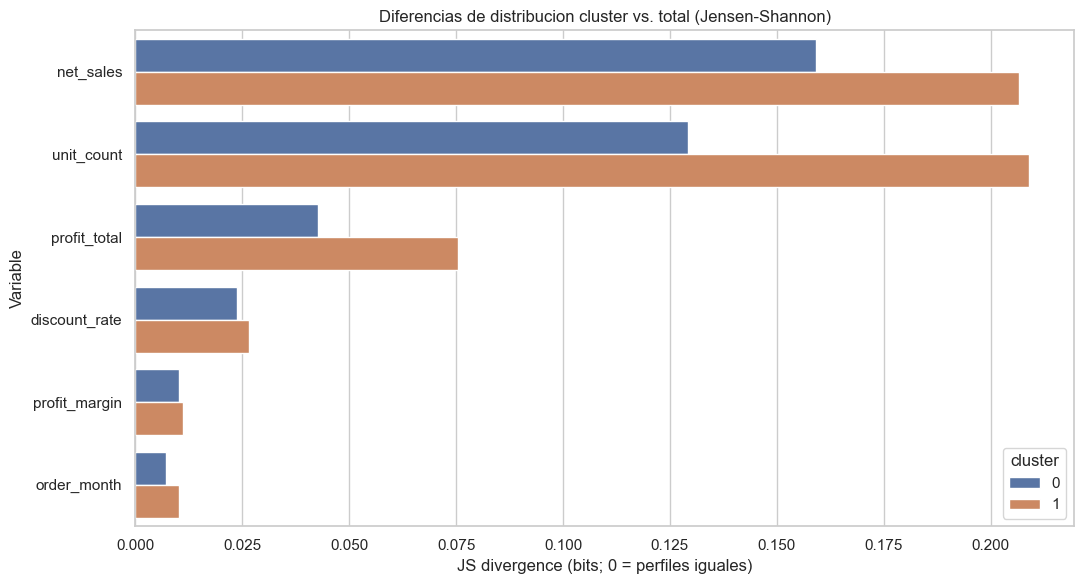

JS media por variable (mayor distingue mas los perfiles):


,JS_bits_media
variable,
net_sales,0.182875
unit_count,0.169107
profit_total,0.059075
discount_rate,0.025153
profit_margin,0.010759
order_month,0.008720
market,0.006103
order_weekday,0.000027
customer_segment,0.000006


In [24]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=top_divergences, x="JS_bits", y="variable", hue="cluster", ax=ax)
ax.set(title="Diferencias de distribucion cluster vs. total (Jensen-Shannon)", xlabel="JS divergence (bits; 0 = perfiles iguales)", ylabel="Variable")
plt.tight_layout()
plt.show()
print("JS media por variable (mayor distingue mas los perfiles):")
display(divergence_table.groupby("variable")["JS_bits"].mean().sort_values(ascending=False).to_frame("JS_bits_media"))

## 8. Validacion temporal

La particion aleatoria anterior no prueba desempeno ante deriva temporal. Como prueba adicional, se entrena K-Means con pedidos anteriores al 2017-10-01 y se evalua en pedidos desde esa fecha hasta el final de la serie. El preprocesador se ajusta solo en el periodo de entrenamiento; el cluster se interpreta descriptivamente, no como pronostico de entrega.

In [25]:
TEMPORAL_CUTOFF = pd.Timestamp("2017-10-01")
temporal_train_mask = model_orders["order_date"] < TEMPORAL_CUTOFF
temporal_eval_mask = ~temporal_train_mask
X_raw_temporal_train = X_raw.loc[temporal_train_mask]
X_raw_temporal_eval = X_raw.loc[temporal_eval_mask]
if len(X_raw_temporal_train) == 0 or len(X_raw_temporal_eval) == 0:
    raise ValueError("The temporal split produced an empty partition.")

temporal_preprocessor = build_preprocessor()
X_temporal_train = temporal_preprocessor.fit_transform(X_raw_temporal_train).astype(np.float64, copy=False)
X_temporal_eval = temporal_preprocessor.transform(X_raw_temporal_eval).astype(np.float64, copy=False)
temporal_kmeans = KMeans(
    n_clusters=best_k, init="k-means++", n_init=20, max_iter=300, random_state=SEED
).fit(X_temporal_train)
temporal_train_labels = temporal_kmeans.labels_
temporal_eval_labels = temporal_kmeans.predict(X_temporal_eval)
temporal_eval_silhouette = silhouette_score(
    X_temporal_eval, temporal_eval_labels,
    sample_size=min(2_500, len(X_temporal_eval)), random_state=SEED,
)
temporal_eval_db = davies_bouldin_score(X_temporal_eval, temporal_eval_labels)
temporal_train_share = pd.Series(temporal_train_labels).value_counts(normalize=True).sort_index()
temporal_eval_share = pd.Series(temporal_eval_labels).value_counts(normalize=True).sort_index()
temporal_js = distribution_divergences(temporal_train_share.to_numpy(), temporal_eval_share.reindex(temporal_train_share.index, fill_value=0).to_numpy())[1]
print(f"Train: {len(X_temporal_train):,} pedidos hasta {TEMPORAL_CUTOFF.date()}; test temporal: {len(X_temporal_eval):,} pedidos desde esa fecha.")
print(f"Silhouette temporal={temporal_eval_silhouette:.4f}; Davies-Bouldin temporal={temporal_eval_db:.4f}; JS entre proporciones cluster train/test={temporal_js:.4f} bits.")
print("Participacion de clusters train:", temporal_train_share.round(3).to_dict())
print("Participacion de clusters test:", temporal_eval_share.round(3).to_dict())
period_label = np.where(temporal_train_mask, "train_pre_cutoff", "test_post_cutoff")
temporal_context = model_orders.assign(period=period_label).groupby("period").agg(
    orders=("Order Id", "size"), mean_lines=("item_count", "mean"),
    mean_units=("unit_count", "mean"), mean_net_sales=("net_sales", "mean"),
    median_net_sales=("net_sales", "median"), mean_profit=("profit_total", "mean"),
).round(2)
print("Temporal feature shift explaining cluster collapse:")
display(temporal_context)
print("Market mix by period (%):")
display((100 * pd.crosstab(model_orders["market"], period_label, normalize="columns")).round(1))


Train: 54,854 pedidos hasta 2017-10-01; test temporal: 8,043 pedidos desde esa fecha.
Silhouette temporal=0.2775; Davies-Bouldin temporal=1.0956; JS entre proporciones cluster train/test=0.3711 bits.
Participacion de clusters train: {0: 0.599, 1: 0.401}
Participacion de clusters test: {0: 0.006, 1: 0.994}
Temporal feature shift explaining cluster collapse:


,orders,mean_lines,mean_units,mean_net_sales,median_net_sales,mean_profit
period,,,,,,
test_post_cutoff,8043,1.02,1.05,271.16,212.42,34.37
train_pre_cutoff,54854,3.00,6.55,537.13,508.84,64.35


Market mix by period (%):


col_0,test_post_cutoff,train_pre_cutoff
market,,
Africa,0.0,6.7
Europe,33.1,27.5
LATAM,0.0,29.9
Pacific Asia,66.9,20.9
USCA,0.0,14.9


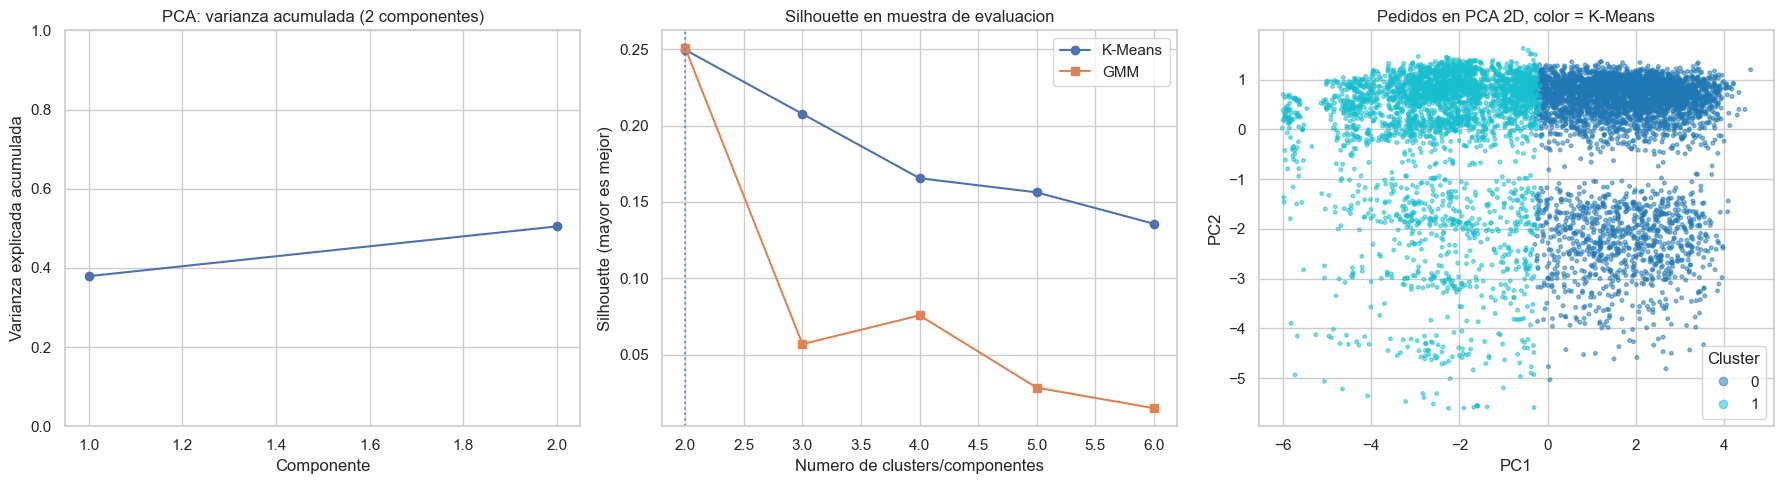

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(np.arange(1, len(pca_2d.explained_variance_ratio_) + 1), np.cumsum(pca_2d.explained_variance_ratio_), marker="o")
axes[0].set(title="PCA: varianza acumulada (2 componentes)", xlabel="Componente", ylabel="Varianza explicada acumulada")
axes[0].set_ylim(0, 1)

axes[1].plot(kmeans_results["k"], kmeans_results["silhouette_eval"], marker="o", label="K-Means")
axes[1].plot(gmm_results["k"], gmm_results["silhouette_eval"], marker="s", label="GMM")
axes[1].axvline(best_k, color="C0", linestyle=":", alpha=0.7)
axes[1].set(title="Silhouette en muestra de evaluacion", xlabel="Numero de clusters/componentes", ylabel="Silhouette (mayor es mejor)")
axes[1].legend()

plot_idx = rng.choice(len(X_pca_2d), size=min(7_000, len(X_pca_2d)), replace=False)
scatter = axes[2].scatter(X_pca_2d[plot_idx, 0], X_pca_2d[plot_idx, 1], c=model_orders["cluster"].to_numpy()[plot_idx], s=7, alpha=0.5, cmap="tab10")
axes[2].set(title="Pedidos en PCA 2D, color = K-Means", xlabel="PC1", ylabel="PC2")
axes[2].legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.tight_layout()
plt.show()

## 9. Detección de anomalías: Isolation Forest

Isolation Forest aísla observaciones mediante particiones aleatorias; puntos que se aíslan en menos pasos reciben puntuaciones más anómalas. Se usa el 1 % inferior de `score_samples` como umbral de revisión (contaminación operativa elegida para priorizar casos, no prevalencia conocida de fraude). El resultado es una lista para investigar, no una etiqueta de error. Las variables de resultado se usan después solo para describir los casos.

In [27]:
isolation_forest = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=SEED,
    n_jobs=-1,
)
isolation_forest.fit(X)
model_orders["anomaly_score"] = isolation_forest.score_samples(X)
ANOMALY_FRACTION = 0.01
anomaly_threshold = model_orders["anomaly_score"].quantile(ANOMALY_FRACTION)
model_orders["is_anomaly_review"] = model_orders["anomaly_score"].le(anomaly_threshold)
print(f"Umbral {ANOMALY_FRACTION:.0%}: {anomaly_threshold:.4f}")
print(f"Casos priorizados: {model_orders['is_anomaly_review'].sum():,} ({model_orders['is_anomaly_review'].mean():.2%})")

anomaly_profile = model_orders.groupby("is_anomaly_review").agg(
    pedidos=("Order Id", "size"),
    net_sales_mediana=("net_sales", "median"),
    utilidad_mediana=("profit_total", "median"),
    unidades_mediana=("unit_count", "median"),
    margen_mediano=("profit_margin", "median"),
    tardanza_riesgo_pct=("late_delivery_risk", lambda s: 100 * s.mean()),
    estado_tardio_pct=("delivery_status", lambda s: 100 * s.eq("Late delivery").mean()),
)
anomaly_profile

Umbral 1%: -0.5334
Casos priorizados: 629 (1.00%)


,pedidos,net_sales_mediana,utilidad_mediana,unidades_mediana,margen_mediano,tardanza_riesgo_pct,estado_tardio_pct
is_anomaly_review,,,,,,,
False,62268,458.665012,73.949997,5.0,0.229609,57.225220,57.225220
True,629,99.959999,-7.980000,1.0,-0.138031,65.977742,65.977742


### Sensibilidad del umbral de anomalias

Se compara la lista priorizada al 0.5 %, 1 % y 2 % de menor puntuacion del mismo Isolation Forest. La interseccion sobre union (Jaccard) respecto al umbral de 1 % indica que casos sobreviven al cambiar la capacidad de revision. Como los umbrales son anidados, esta comparacion es sensibilidad de politica, no una repeticion independiente del modelo.

In [28]:
base_flags = model_orders["anomaly_score"].le(model_orders["anomaly_score"].quantile(0.01)).to_numpy()
threshold_rows = []
for fraction in [0.005, 0.01, 0.02]:
    threshold = model_orders["anomaly_score"].quantile(fraction)
    flags = model_orders["anomaly_score"].le(threshold).to_numpy()
    union = np.logical_or(flags, base_flags).sum()
    intersection = np.logical_and(flags, base_flags).sum()
    cases = model_orders.loc[flags]
    threshold_rows.append({
        "fraccion_priorizada": fraction,
        "casos": int(flags.sum()),
        "umbral_score": threshold,
        "Jaccard_vs_1pct": intersection / union if union else 1.0,
        "mediana_ventas_netas": cases["net_sales"].median(),
        "mediana_utilidad": cases["profit_total"].median(),
        "tardanza_pct_descriptiva": 100 * cases["late_delivery_risk"].mean(),
    })
anomaly_sensitivity = pd.DataFrame(threshold_rows)
anomaly_sensitivity

,fraccion_priorizada,casos,umbral_score,Jaccard_vs_1pct,mediana_ventas_netas,mediana_utilidad,tardanza_pct_descriptiva
0,0.005,315,-0.540941,0.500795,58.790001,-7.680000,62.222222
1,0.010,629,-0.533397,1.000000,99.959999,-7.980000,65.977742
2,0.020,1258,-0.525911,0.500000,129.990005,-5.505002,69.872814


### Comparacion no supervisada de detectores de anomalias

Se comparan Isolation Forest, Local Outlier Factor (LOF) en modo novelty y error de reconstruccion PCA sobre la misma muestra de evaluacion. Cada detector prioriza su 1 % mas extremo; se informa Jaccard entre pares y caracteristicas economicas. No hay etiquetas de anomalia verdaderas, por lo que no se calcula precision/recall ni se declara un metodo ganador.

La comparacion usa 40 casos por detector (1 % de los 4.000 pedidos de evaluacion); solapamientos bajos indican que los metodos ordenan nociones distintas de atipicidad. Sin etiquetas externas no se puede decidir cual es mas preciso.

In [29]:
IF_eval_model = IsolationForest(
    n_estimators=200, contamination="auto", random_state=SEED, n_jobs=-1
).fit(X_train)
if_eval_score = IF_eval_model.score_samples(X_eval)  # menor = mas anomalo
lof_model = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination="auto", n_jobs=-1).fit(X_train)
lof_eval_score = lof_model.score_samples(X_eval)  # menor = mas anomalo
pca_residual_model = PCA(n_components=17, svd_solver="full").fit(X_train)
X_eval_reconstructed = pca_residual_model.inverse_transform(pca_residual_model.transform(X_eval))
pca_reconstruction_error = np.linalg.norm(X_eval - X_eval_reconstructed, axis=1)  # mayor = mas anomalo

score_vectors = {
    "Isolation Forest": -if_eval_score,
    "LOF novelty": -lof_eval_score,
    "PCA residual": pca_reconstruction_error,
}
flag_vectors = {}
for method, scores in score_vectors.items():
    threshold = np.quantile(scores, 0.99)
    flag_vectors[method] = scores >= threshold

anomaly_comparison_rows = []
for left, right in [("Isolation Forest", "LOF novelty"), ("Isolation Forest", "PCA residual"), ("LOF novelty", "PCA residual")]:
    intersection = np.logical_and(flag_vectors[left], flag_vectors[right]).sum()
    union = np.logical_or(flag_vectors[left], flag_vectors[right]).sum()
    anomaly_comparison_rows.append({"detector_a": left, "detector_b": right, "Jaccard_top_1pct": intersection / union})
anomaly_method_agreement = pd.DataFrame(anomaly_comparison_rows)

eval_orders = model_orders.iloc[eval_idx].reset_index(drop=True)
method_profiles = []
for method, flags in flag_vectors.items():
    flagged = eval_orders.loc[flags]
    method_profiles.append({
        "detector": method, "flagged": int(flags.sum()), "share_pct": 100 * flags.mean(),
        "median_net_sales": flagged["net_sales"].median(),
        "median_profit": flagged["profit_total"].median(),
        "late_risk_pct_descriptive": 100 * flagged["late_delivery_risk"].mean(),
    })
print("Pairwise top-1% overlap (Jaccard):")
display(anomaly_method_agreement)
print("Descriptive profile of top-1% anomaly candidates:")
display(pd.DataFrame(method_profiles).round(3))

Pairwise top-1% overlap (Jaccard):


,detector_a,detector_b,Jaccard_top_1pct
0,Isolation Forest,LOF novelty,0.052632
1,Isolation Forest,PCA residual,0.081081
2,LOF novelty,PCA residual,0.038961


Descriptive profile of top-1% anomaly candidates:


,detector,flagged,share_pct,median_net_sales,median_profit,late_risk_pct_descriptive
0,Isolation Forest,40,1.0,49.730,-5.405,70.0
1,LOF novelty,40,1.0,598.680,24.690,65.0
2,PCA residual,40,1.0,304.835,-48.025,57.5


## 10. Hallazgos, alcance y limitaciones

### Lectura de los resultados de esta ejecucion

- K-Means selecciona dos perfiles con silhouette aproximado de 0.25 y ARI medio de 0.998 entre semillas. El grupo mayor (55.9 %) tiene ventas netas promedio cercanas a 705 unidades monetarias y 8.6 unidades por pedido; el otro (44.1 %) tiene 248 y 2.4, respectivamente. Ambos tienen margen medio cercano a 12 % y riesgo de tardanza alrededor de 57 %. La separacion parece describir principalmente el tamano/valor del pedido, no un mejor servicio de entrega.
- GMM con seis componentes obtiene el BIC minimo entre los valores probados, pero su silhouette de evaluacion es cercano a 0.015 y Davies-Bouldin alto. Por eso no se prefiere como segmentacion operativa: el ajuste de densidad y la separacion geometrica responden a criterios diferentes.
- Isolation Forest prioriza 629 pedidos (1 %). Su mediana de venta neta es cercana a 100 y su utilidad mediana es negativa (aprox. -8), frente a 459 y 74 en los demas pedidos. Son candidatos a revision, no errores confirmados.
- Se hallaron 180.519/180.519 filas con `Product Description` vacia; `Order Zipcode` falta en 86.2 %. La etiqueta de riesgo coincide con `Delivery Status`, pero difiere en 2.45 % de comparar directamente dias reales con dias programados.

- La estabilidad por submuestras fue ARI=0.988; PCA-2D obtuvo trustworthiness=0.865 frente a 0.685 de la proyeccion aleatoria, aunque solo retiene 50.2 % de varianza en dos dimensiones. La JS media destaca ventas netas (0.183) y unidades (0.169), coherente con perfiles definidos sobre todo por magnitud del pedido.
- El GMM muestra posterior medio maximo de 0.998 y entropia normalizada 0.003, pese a silhouette bajo (0.015): la confianza interna del modelo no garantiza una geometria de clusters util; interpretar esta aparente certeza con cautela.
- Cambiar la capacidad de revision de 1 % a 0.5 % o 2 % produce Jaccard=0.501/0.500 contra la lista base, lo cual refleja umbrales anidados y que hay casos fronterizos; no es una validacion independiente.

Estas metricas se recalculan al ejecutar las celdas y deben interpretarse junto con las tablas de perfiles. La interpretacion debe centrarse en variables que diferencian cada cluster (tamano, cantidad, ventas, descuento, margen, plazo, segmento, mercado y modo), no asignar significado causal a los IDs de cluster.

- Silhouette mas alto favorece separacion geometrica, pero puede premiar una particion gruesa; BIC penaliza complejidad dentro de GMM, pero no prueba que exista una "verdad" de grupos.
- PCA es lineal y sensible a escala; su proyeccion 2D puede ocultar estructura. Las mezclas gaussianas con covarianza diagonal son una simplificacion; K-Means favorece grupos aproximadamente esfericos. Ambos dependen de la representacion y las inicializaciones.
- La estabilidad entre semillas y tamanos de cluster ayudan a juzgar robustez, pero no sustituyen validacion temporal o utilidad operacional. Los datos historicos contienen una ventana limitada y clases desbalanceadas por mercado/modo.
- La tasa `Late_delivery_risk` no coincide perfectamente con comparar dias reales contra programados; ademas los estados de entrega no deben tratarse como verdad sin revisar su semantica. Se reservaron del ajuste para evitar fuga y se reportan solo como contexto posterior.
- Isolation Forest no conoce el costo de falsos positivos; el 1 % es una capacidad de revision supuesta. Analizar casos con contexto antes de tomar decisiones.
- El dataset ofrece metricas operativas y financieras historicas; los segmentos no identifican causas ni garantizan decisiones de despacho futuras. Los logs se excluyeron por falta de llave transaccional, cobertura parcial de productos/tiempo y presencia de IP.
- Se retiraron atributos personales y no se incluyeron geografia de cliente, ciudades ni identificadores en la matriz de modelado; persisten sesgos de cobertura y representacion del dataset original.

Las pruebas adicionales informan sensibilidad a covarianza del GMM, variacion temporal, redundancia de ventas, composicion de mercado y desacuerdo entre detectores de anomalias. Sus resultados y unidades se imprimen en las tablas anteriores; no deben interpretarse como causalidad ni como etiquetas supervisadas.

### Resultado de las pruebas adicionales

- **Validacion cruzada (5 pliegues):** PCA/PPCA con 17 componentes obtuvo log-verosimilitud media por observacion ?14.948 ? 0.128; GMM diagonal con k=6 obtuvo 8.177 ? 3.961. Son scores por observacion bajo dos familias de densidad; no comparar sin considerar supuestos, transformacion y muestras.
- **Covarianza GMM:** en la misma submuestra de 4.000 pedidos, covarianza full fue mejor por BIC tanto para k=2 (?221.041) como k=6 (?267.627), frente a tied, diagonal y spherical. En CV pareada para k=6, full obtuvo 37.907 ? 3.110 y diag 3.728 ? 8.968. Es evidencia de sensibilidad, no seleccion exhaustiva de k para cada estructura; full tiene >5.000 parametros de covarianza a 42 dimensiones y requiere cautela.
- **Mercado:** al quitar `market`, ARI frente al modelo completo = 0.985. En evaluacion, la asignacion sin Market aun se asocia con Market (chi-cuadrado=149.58, p=2.50e?31, V de Cramer=0.193). La particion no depende exclusivamente de Market, pero tampoco es independiente del mercado.
- **Redundancia de ventas:** gross/net sales correlacionan 0.995737. Al quitar `gross_sales_log` y conservar `net_sales_log`, ARI frente al baseline=0.9216; silhouette=0.2367 y Davies?Bouldin=1.5982. La estructura se conserva en gran medida, aunque la asignacion cambia en algunos pedidos.
- **Acuerdo K-Means/GMM:** ARI en los mismos 4.000 pedidos = 0.533 para K-Means k=2 vs GMM k=2 y 0.239 para K-Means k=2 vs GMM k=6 seleccionado por BIC. No son particiones equivalentes.
- **Deriva temporal:** entrenando hasta 2017-09-30 (54.854 pedidos) y probando desde 2017-10-01 (8.043 pedidos), la silueta temporal fue 0.2775 y Davies?Bouldin 1.0956, pero la participacion de clusters cambi? de 59.9/40.1 % a 0.6/99.4 % (JS=0.3711 bits). El test tardio tambien tiene 1.02 lineas y venta neta media 271.16 vs 3.00 lineas y 537.13 en train, y solo representa Europe/Pacific Asia. Esta deriva impide tratar el resultado aleatorio como evidencia de estabilidad futura.
- **Detectores de anomalias:** en la misma evaluacion, la interseccion top 1 % fue baja: Jaccard 0.053 entre Isolation Forest y LOF, 0.081 entre Isolation Forest y residual PCA, y 0.039 entre LOF y residual PCA. Sin etiquetas verdaderas no se puede afirmar cual detecta mejor.
- **Perfiles:** IC bootstrap percentile 95 % (500 remuestreos dentro de cluster): net_sales media cluster 0 [702.33, 707.47], cluster 1 [245.60, 250.03]; utilidad media [82.20, 86.56] y [28.57, 31.90]; unidades medias [8.55, 8.62] y [2.36, 2.40]. Condicionados a la particion; no son intervalos de incertidumbre de asignacion.


In [30]:
print("RESUMEN EJECUTIVO DE RESULTADOS")
print(f"Datos limpios: {len(clean):,} lineas x {clean.shape[1]} columnas; pedidos modelados={len(model_orders):,}.")
print(f"PCA: {pca_90.n_components_} componentes para {pca_90.explained_variance_ratio_.sum():.1%}; 2D={pca_2d.explained_variance_ratio_.sum():.1%}; trustworthiness={trust_pca:.3f}.")
print(f"K-Means k={best_k}: silhouette={best_kmeans_eval['silhouette_eval']:.3f}, Davies-Bouldin={best_kmeans_eval['davies_bouldin_eval']:.3f}, ARI seeds={np.mean(ari_values):.3f}, ARI subsamples={np.mean(subsample_ari):.3f}.")
print(f"GMM diag k={best_gmm_k}: BIC={best_gmm_eval['bic_train']:.1f}, silhouette={best_gmm_eval['silhouette_eval']:.3f}; posterior max mean={gmm_uncertainty['max_posterior_media']:.3f}.")
print(f"CV 5-fold PCA/PPCA (17)={cv_loglikelihood.loc[0, 'logverosimilitud_media_cv']:.3f} +/- {cv_loglikelihood.loc[0, 'desviacion_entre_pliegues']:.3f}; GMM diag k=6={cv_loglikelihood.loc[1, 'logverosimilitud_media_cv']:.3f} +/- {cv_loglikelihood.loc[1, 'desviacion_entre_pliegues']:.3f}.")
print(f"Market ablation: ARI={ari_market_ablation:.3f}, Cramer's V={market_cramers_v:.3f}, p={p_market:.3g}; sin gross_sales_log: ARI={ari_no_gross:.3f}.")
print("K-Means/GMM ARI:", model_agreement.set_index("comparacion")["ARI_evaluacion"].round(3).to_dict())
print(f"Deriva temporal (test n={len(X_temporal_eval):,}): silhouette={temporal_eval_silhouette:.3f}, JS proporciones={temporal_js:.3f} bits, cluster shares={temporal_eval_share.round(3).to_dict()}.")
print("Anomaly detector Jaccard IF-LOF, IF-PCA, LOF-PCA:", anomaly_method_agreement["Jaccard_top_1pct"].round(3).tolist())
display(profile.sort_values("pedidos", ascending=False))
display(cv_loglikelihood)
display(covariance_comparison)
display(profile_confidence_intervals)
display(anomaly_sensitivity)
display(anomaly_method_agreement)

RESUMEN EJECUTIVO DE RESULTADOS
Datos limpios: 180,519 lineas x 31 columnas; pedidos modelados=62,897.
PCA: 17 componentes para 90.8%; 2D=50.5%; trustworthiness=0.865.
K-Means k=2: silhouette=0.250, Davies-Bouldin=1.533, ARI seeds=0.998, ARI subsamples=0.988.
GMM diag k=6: BIC=-132866.6, silhouette=0.015; posterior max mean=0.998.
CV 5-fold PCA/PPCA (17)=-14.948 +/- 0.128; GMM diag k=6=8.177 +/- 3.961.
Market ablation: ARI=0.985, Cramer's V=0.193, p=2.5e-31; sin gross_sales_log: ARI=0.922.
K-Means/GMM ARI: {'K-Means k=2 vs GMM k=2': 0.533, 'K-Means k=2 vs GMM k=6 (BIC)': 0.239}
Deriva temporal (test n=8,043): silhouette=0.277, JS proporciones=0.371 bits, cluster shares={0: 0.006, 1: 0.994}.
Anomaly detector Jaccard IF-LOF, IF-PCA, LOF-PCA: [0.053, 0.081, 0.039]


,pedidos,ventas_netas_promedio,ventas_netas_mediana,utilidad_promedio,margen_promedio,unidades_promedio,lineas_promedio,plazo_programado_promedio,dias_reales_promedio,riesgo_tardanza_pct,tardios_por_estado_pct,participacion_pct
cluster,,,,,,,,,,,,
0,35127,705.06,675.72,84.42,0.12,8.58,3.86,2.93,3.5,57.30,57.30,55.85
1,27770,247.68,219.86,30.28,0.12,2.38,1.33,2.94,3.5,57.32,57.32,44.15


,modelo,k_o_componentes,logverosimilitud_media_cv,desviacion_entre_pliegues
0,PCA probabilistico (17 componentes),17,-14.947558,0.12799
1,GMM diagonal (k=6),6,8.176878,3.96090


,k,covariance_type,bic,aic,loglik_mean_train,converged,iterations
0,2,full,-221041.052276,-232943.100145,29.590638,True,11
1,2,tied,-73174.112949,-79392.633993,10.171079,True,4
2,2,diag,173232.336031,172168.641642,-21.478830,True,13
3,2,spherical,250105.866194,249558.283876,-31.173035,True,4
4,6,full,-267626.978680,-303345.710387,39.336964,True,19
5,6,tied,-83568.689177,-90869.786760,11.648723,True,9
6,6,diag,-20169.779868,-23373.451134,3.048931,True,19
7,6,spherical,208789.671329,207134.336274,-25.826042,True,5


,cluster,metric,n,mean,ci95_low,ci95_high
0,0,net_sales,35127,705.057136,702.329926,707.474060
1,0,profit_total,35127,84.422124,82.196464,86.562055
2,0,unit_count,35127,8.582913,8.549328,8.616376
3,1,net_sales,27770,247.681781,245.598487,250.032884
4,1,profit_total,27770,30.281767,28.569202,31.896362
5,1,unit_count,27770,2.380230,2.358930,2.398777


,fraccion_priorizada,casos,umbral_score,Jaccard_vs_1pct,mediana_ventas_netas,mediana_utilidad,tardanza_pct_descriptiva
0,0.005,315,-0.540941,0.500795,58.790001,-7.680000,62.222222
1,0.010,629,-0.533397,1.000000,99.959999,-7.980000,65.977742
2,0.020,1258,-0.525911,0.500000,129.990005,-5.505002,69.872814


,detector_a,detector_b,Jaccard_top_1pct
0,Isolation Forest,LOF novelty,0.052632
1,Isolation Forest,PCA residual,0.081081
2,LOF novelty,PCA residual,0.038961


## 11. Referencias metodológicas

- Akaike, H. (1974). *A new look at the statistical model identification*. IEEE Transactions on Automatic Control, 19(6), 716-723. https://doi.org/10.1109/TAC.1974.1100705
- Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). *Maximum likelihood from incomplete data via the EM algorithm*. Journal of the Royal Statistical Society: Series B, 39(1), 1-38.
- Jolliffe, I. T. (2002). *Principal Component Analysis* (2nd ed.). Springer.
- Liu, F. T., Ting, K. M., & Zhou, Z.-H. (2008). *Isolation Forest*. 2008 IEEE International Conference on Data Mining, 413-422. https://doi.org/10.1109/ICDM.2008.17
- MacQueen, J. (1967). *Some methods for classification and analysis of multivariate observations*. Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability, 1, 281-297.
- Schwarz, G. (1978). *Estimating the dimension of a model*. The Annals of Statistics, 6(2), 461-464.
- Breunig, M. M., Kriegel, H.-P., Ng, R. T., & Sander, J. (2000). LOF: Identifying Density-Based Local Outliers. *Proceedings of the ACM SIGMOD International Conference on Management of Data*, 93?104. https://doi.org/10.1145/342009.335388
- Lin, J. (1991). Divergence measures based on the Shannon entropy. *IEEE Transactions on Information Theory*, 37(1), 145?151. https://doi.org/10.1109/18.61115


## Anexo: guia autocontenida para la sustentacion escrita

Este anexo permite responder el formato de sustentacion usando solamente este notebook. El estudiante debe revisar y expresar las respuestas con su propia voz. No atribuir causalidad a los clusters.

### I. Planteamiento y datos

**a) Pregunta.** ?Se pueden identificar perfiles de pedidos por composicion y valor economico, y condiciones de despacho planificadas, y priorizar pedidos atipicos para revision?

**b) Entradas y variables reservadas.** La matriz de 42 variables incluye 11 variables numericas (conteos, ventas/descuento, utilidad/margen, diversidad de productos/categorias y plazo programado) y one-hot para modo, mercado, segmento, mes y dia de semana. Se reservaron dias reales, estado de entrega, riesgo y estado de pedido; los IDs tampoco se modelaron. Esto evita que el agrupamiento vea directamente el resultado que luego se interpreta.

**c) Retraso negativo.** Definicion: dias reales menos dias programados. Hay 43.366 lineas negativas en la fuente; 15.787 pedidos al agregar, de los que 660 son cancelados. Entre pedidos enviados/modelados hay 15.127 con retraso negativo. Significa envio anticipado; no se imputaron ni borraron esos registros por ese motivo.

**d) Variables correlacionadas.** gross_sales y net_sales agregados tienen Pearson r=0.995737. Ambas entraron transformadas; quitar gross_sales_log dio ARI=0.9216 respecto al baseline, silhouette=0.2367 y DB=1.5982. Es una sensibilidad importante: la particion sigue bastante parecida, aunque hay cambios y el espacio original pesa ventas duplicadamente.

**e) Transformacion antes de PCA.** log1p para cantidades/montos positivos sesgados; arcsinh para utilidad/margen con negativos; StandardScaler para variables numericas y one-hot para categorias. Evita que la escala de dolares o las colas dominen por magnitud. La varianza de PCA es la del espacio transformado, no de las unidades monetarias originales.

### II. Modelo latente o de mezcla

**a) PCA clasico vs probabilistico.** El PCA clasico proyecta maximizando varianza; PCA probabilistico interpreta las observaciones mediante variables latentes gaussianas y ruido, permitiendo puntuacion de verosimilitud. Aqui se aplico PCA clasico; `PCA.score` se uso adicionalmente como verosimilitud bajo el modelo probabilistico implicito de scikit-learn, no se ajusto un PPCA separado.

**b) Componentes.** 17 componentes alcanzan 90.8 % de varianza en entrenamiento. Las dos primeras explican 50.22 % (PC1=37.61 %, PC2=12.61 %).

**c) PC1.** Cargas absolutas principales: item_count_log 0.4005, distinct_products 0.3896, distinct_categories 0.3896, gross_sales_log 0.3779, net_sales_log 0.3748, unit_count_log 0.3676 y discount_amount_log 0.3341. Se interpreta como magnitud/composicion/valor del pedido; cargas no son efectos causales.

**d) Log-verosimilitud en CV.** CV de cinco pliegues, con preprocesador ajustado dentro de cada pliegue: PCA/PPCA implicito de 17 componentes ?14.9476 ? 0.1280 por observacion; GMM diagonal k=6 8.1769 ? 3.9609. Son puntuaciones de densidad de familias distintas. El GMM full, en una CV pareada aparte de cinco pliegues sobre la misma submuestra de 4.000 pedidos para k=6, obtuvo 37.9068 ? 3.1101, frente a diagonal 3.7280 ? 8.9676. No mezclar estos dos esquemas de CV.

**e) PC2.** Domina profit_margin_asinh (0.7058) y profit_total_asinh (0.7045), por lo que refleja variacion economica de margen/utilidad que no domina PC1. En dos dimensiones se retiene solo 50.22 %; trustworthiness con 15 vecinos=0.865, frente a proyeccion aleatoria 0.685.

### III. Tecnica de comparacion

**a) K-Means.** Se eligio k=2: silhouette evaluacion 0.249680, Davies?Bouldin 1.533249. Los grupos tienen 35.127 (55.85 %) y 27.770 (44.15 %) pedidos. ARI entre semillas media=0.998 ? 0.001; sobre submuestras de 80 % media=0.988 ? 0.007.

**b) Funcion objetivo.** K-Means minimiza `sum_i min_k ||x_i - mu_k||^2`, donde `x_i` es un vector de pedido y `mu_k` el centroide de su cluster.

**c) Covarianza GMM y BIC.** El barrido principal uso diagonal, k=2?6, y el menor BIC diagonal fue k=6: ?132.866,6; silhouette=0.014857. En una comparacion exploratoria de covarianzas en la misma submuestra de 4.000, full tuvo menor BIC para k=2 (?221.041,1) y k=6 (?267.627,0); en k=6, tied ?83.568,7; diag ?20.169,8; spherical 208.789,7. Full tambien gano la CV pareada, pero tiene >5.000 parametros de covarianza a 42 dimensiones. No se probaron todos los k para cada tipo; describir esta conclusion como sensibilidad, no como seleccion exhaustiva definitiva.

**d) Frontera GMM.** Definiendo frontera como max(probabilidad posterior)<0.8, hay 8 de 4.000 observaciones (0.2 %) en la evaluacion. GMM k=6 tiene posterior maximo medio=0.998 y entropia normalizada media=0.003; pese a ello su silhouette es bajo, por lo que la confianza interna no prueba separacion util.

**e) K-Means vs GMM.** ARI sobre exactamente los mismos pedidos de evaluacion: K-Means k=2 vs GMM k=2 =0.533; K-Means k=2 vs GMM k=6 seleccionado por BIC =0.239. K-Means asigna por distancia a centroides; GMM asigna probabilidades bajo densidades gaussianas. No son particiones equivalentes, sobre todo con distinto numero de componentes.

### IV. Validacion e interpretacion

**a) Estabilidad.** Semillas [7,21,42,73,101], ARI por pares [0.996,1.000,0.999,0.999,0.996,0.997,0.997,0.999,0.999,1.000]; media 0.998, desviacion 0.001. Submuestras: ARI 0.988 ? 0.007.

**b) Silhouette.** 0.249680 para k=2 en la evaluacion aleatoria de 4.000 pedidos.

**c) Davies?Bouldin.** 1.533249. Menor suele indicar clusters mas compactos y separados en esta representacion, pero depende de la geometria y el escalado.

**d) Region.** Sin `market` como entrada, ARI contra el baseline=0.9851. Aun asi, cluster sin Market y mercado se asocian en la muestra de evaluacion: chi-cuadrado=149.58, p=2.502e?31, V de Cramer=0.1934. La particion no depende exclusivamente de Market, pero no es independiente de mercado; existen diferencias de composicion y no deben ocultarse.

**e) Grafica.** En el scatter PCA, eje X=PC1 y eje Y=PC2 (scores sin unidades fisicas), color/leyenda=cluster K-Means, 7.000 puntos muestreados. Dos PCs explican 50.22 %; la grafica es exploratoria. Silhouette valida separacion en el espacio de 42 caracteristicas, no en la proyeccion 2D.

### V. Integracion y decision

**a) Sesgo regional.** La fuente tiene cobertura desigual y la mezcla de mercado cambia: cluster 0 tiene LATAM 30.2 % y Pacific Asia 20.4 %; cluster 1, LATAM 21.0 % y Pacific Asia 34.8 %. En la prueba temporal tardia solo hay Europe/Pacific Asia (33.1/66.9 %). Los perfiles pueden reflejar cobertura y cambios geograficos, no una regla universal.

**b) Riesgo de inventario.** Los grupos describen principalmente magnitud de pedido, no demanda futura, rotacion, lead time por producto, capacidad ni costos de faltantes/exceso. Usarlos directamente para inventario puede sobreabastecer o dejar faltantes; se requeriria pronostico temporal y validacion operacional.

**c) Conclusion respaldada.** En el periodo/modelo aleatorio hay dos perfiles estables que difieren sobre todo en valor y unidades; ambos tienen riesgo de tardanza cercano a 57.3 %. La prueba temporal contradice una estabilidad futura simple: posterior a 2017-10-01, la proporcion de cluster 0 cae a 0.6 % y el promedio de lineas baja de 3.00 a 1.02. Se requieren monitoreo/reentrenamiento antes de uso operativo.

**d) Conclusion no sustentable.** No se puede afirmar que pertenecer al cluster 0 cause mayor utilidad, que reduzca retrasos, ni que la segmentacion prediga inventario futuro con buen desempeno: no hay experimento causal ni validacion de politica de inventario.

**e) Tres frases para gerencia.** ?El analisis separa pedidos principalmente por tamano y valor, no por una diferencia apreciable en retrasos. Los grupos son estables en muestras aleatorias, pero la composicion cambia fuertemente en los pedidos mas recientes, por lo que no recomendamos usar la segmentacion para asignar inventario sin validacion temporal. Se requiere monitorear mercados, demanda y costos, y revisar pedidos atipicos como candidatos, no como errores confirmados.?

### Guia de limites

- El 1 % de Isolation Forest es una capacidad de revision supuesta, no una prevalencia verdadera. En 4.000 pedidos, IF, LOF y residual PCA marcaron 40 casos cada uno; Jaccard IF?LOF=0.0526, IF?PCA=0.0811, LOF?PCA=0.0390. No hay etiquetas verdaderas para precision/recall.
- Las medianas de ventas netas/utilidad de IF en la poblacion completa priorizada (629) son 99.96 y ?7.98. En los 40 candidatos IF de la evaluacion, son 49.73 y ?5.405; no intercambiar muestras.
- IC bootstrap 95 % de medias, remuestreo dentro del cluster (500 repeticiones): venta neta cluster 0 [702.33,707.47], cluster 1 [245.60,250.03]; utilidad [82.20,86.56] y [28.57,31.90]; unidades [8.55,8.62] y [2.36,2.40]. Son condicionales a las etiquetas halladas.
- Log-verosimilitudes de PCA y GMM dependen del espacio transformado y de los pliegues; la CV pareada de covarianzas usa solo un subconjunto de 4.000. El BIC de covariance full puede favorecer un modelo muy parametrizado; revisar convergencia, regularizacion y generalizacion.
- Ningun resultado identifica causas ni sustituye una evaluacion de impacto/servicio en produccion.